# Paths and Load files



In [2]:

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import os

os.chdir("/home/jorge/Escritorio/Proy_cosmo/Cosmo_MSc")

from src.core.paths import PathManager
from src.simulations.cmb_simulator import CmbSimulator
from src.simulations.foreground_simulator import ForegroundSimulator
from src.simulations.config import Config, CmbConfig, ForegroundConfig, NoiseConfig


## Crear espectros

Para crear y guardar espectros se utiliza la clase CmbSimulator

[CAMB] Computing spectra: total, unlensed_total, lens_potential, tensor, unlensed_scalar
[SAVE] CMB spectra: /home/jorge/Escritorio/Proy_cosmo/Cosmo_MSc/outputs_main/simulations/cmb/cls/r_0.00000/lmax_3000.npz


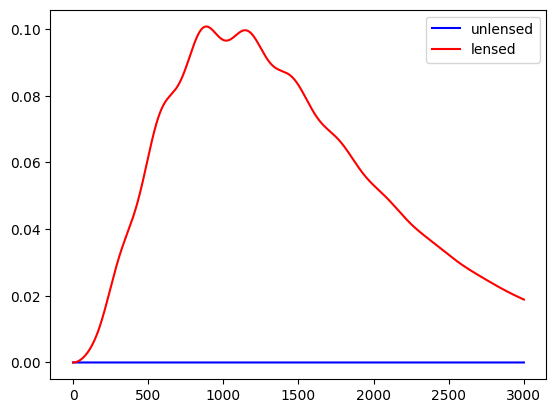

In [ ]:
# Configuración necesaria
cmb_config = CmbConfig(
    nside = 2048,
    nsim = 1,
    lmax = 3000,
    r = 0.00,
    )

config = Config(
    base_dir="outputs_main",
    cmb=cmb_config
)

# Instancia de CmbSimulator
simulator = CmbSimulator(config=config)

paths = PathManager(config.base_dir)

# Diccionario de espectros powers["total"] retorna el espectro total
# Tambien los guarda en carpeta
# Retorna los espectros con raw_cl = True y  CMB_unit = muK
powers = simulator.compute_cls(names=["total", "unlensed_total", "lens_potential", "tensor", "unlensed_scalar"], overwrite=True)

cl_unl = powers["unlensed_total"]

cl_phi = powers["lens_potential"][:,0] # este retorna \phi\phi | T\phi | E\phi por eso el [:,0]

cl_len = powers["total"]

ell = np.arange(config.cmb.lmax + 1)
factor = ell*(ell+1)/(2*np.pi) # To compute D_l

#plot espectros C^{BB}
plt.plot(ell, cl_unl[:, 2]*factor, label="unlensed", color="b")
plt.plot(ell, cl_len[:, 2]*factor, label="lensed", color="r")
plt.legend()
plt.show()


## Generar realizaciones de CMB mediante los espectros  

Se utiliza la función simulate_one(), notar que es una función heredada, pero definida en CmbSimulator. 

Consideración importante no estamos tomando en cuenta los espectros $C^{T \phi}_\ell$, $C^{E \phi}_\ell$ para generar los mapas, esto como aproximación funciona ya que solo te interesa el efecto de lensing, pero es algo a considerar.

Si queremos verificar que nuestras realizaciones siguen la estadística descrita por CAMB, es necesario calcular el espectro de cada una y promediar.

$$ C_\ell^{fid} \approx \left< \hat C_\ell \right> $$



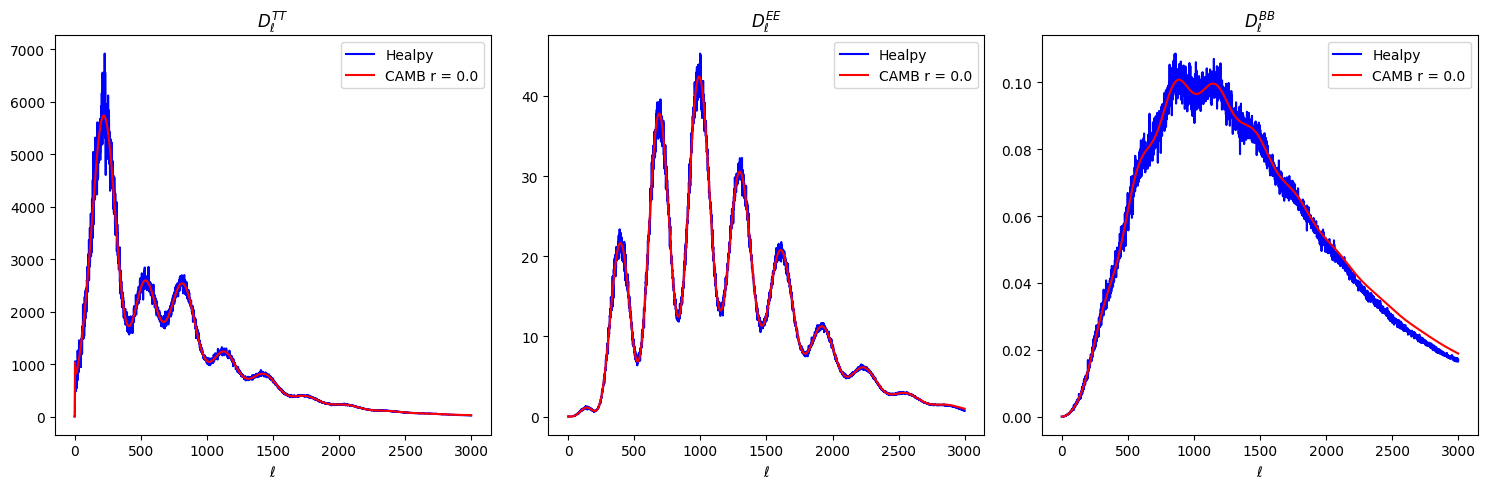

In [ ]:
names = ["T", "E", "B"]

# -------------- Mean Cls -----------------

mean_Cl_ls = np.zeros((3, config.cmb.lmax+1), dtype=float)  # TT, EE, BB
mean_Cl_ul = np.zeros((3, config.cmb.lmax+1), dtype=float)
# mean_Cl_TE = 0
for sim in range(config.cmb.nsim):

    alm_lensed = simulator.simulate_one(cls=[cl_unl, cl_phi], sim = sim)

    # lista de alms orden T, E y B 
    for j, name in enumerate(names):

        alm_len = alm_lensed[j] 

        mean_Cl_ls[j] += hp.sphtfunc.alm2cl(alm_len, alm_len, lmax=config.cmb.lmax)*factor


mean_Cl_ls = mean_Cl_ls/config.cmb.nsim
mean_Cl_ul = mean_Cl_ul/config.cmb.nsim


fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].plot(ell, mean_Cl_ls[0],color='b',label='Healpy') 
ax[0].plot(ell, cl_len[:, 0]*factor,color="r",label=f"CAMB r = {config.cmb.r}")
ax[0].set_title(r'$D_\ell^{TT}$')
ax[0].legend()
ax[0].set_xlabel(r'$\ell$')

ax[1].plot(ell, mean_Cl_ls[1],color='b',label='Healpy') 
ax[1].plot(ell, cl_len[:, 1]*factor,color="r",label=f"CAMB r = {config.cmb.r}")
ax[1].set_title(r'$D_\ell^{EE}$')
ax[1].legend()
ax[1].set_xlabel(r'$\ell$')

ax[2].plot(ell, mean_Cl_ls[2],color='b',label='Healpy') 
ax[2].plot(ell, cl_len[:, 2]*factor,color="r",label=f"CAMB r = {config.cmb.r}")
ax[2].set_title(r'$D_\ell^{BB}$')
ax[2].legend()
ax[2].set_xlabel(r'$\ell$')

plt.tight_layout()
plt.show()

## Maps CMB

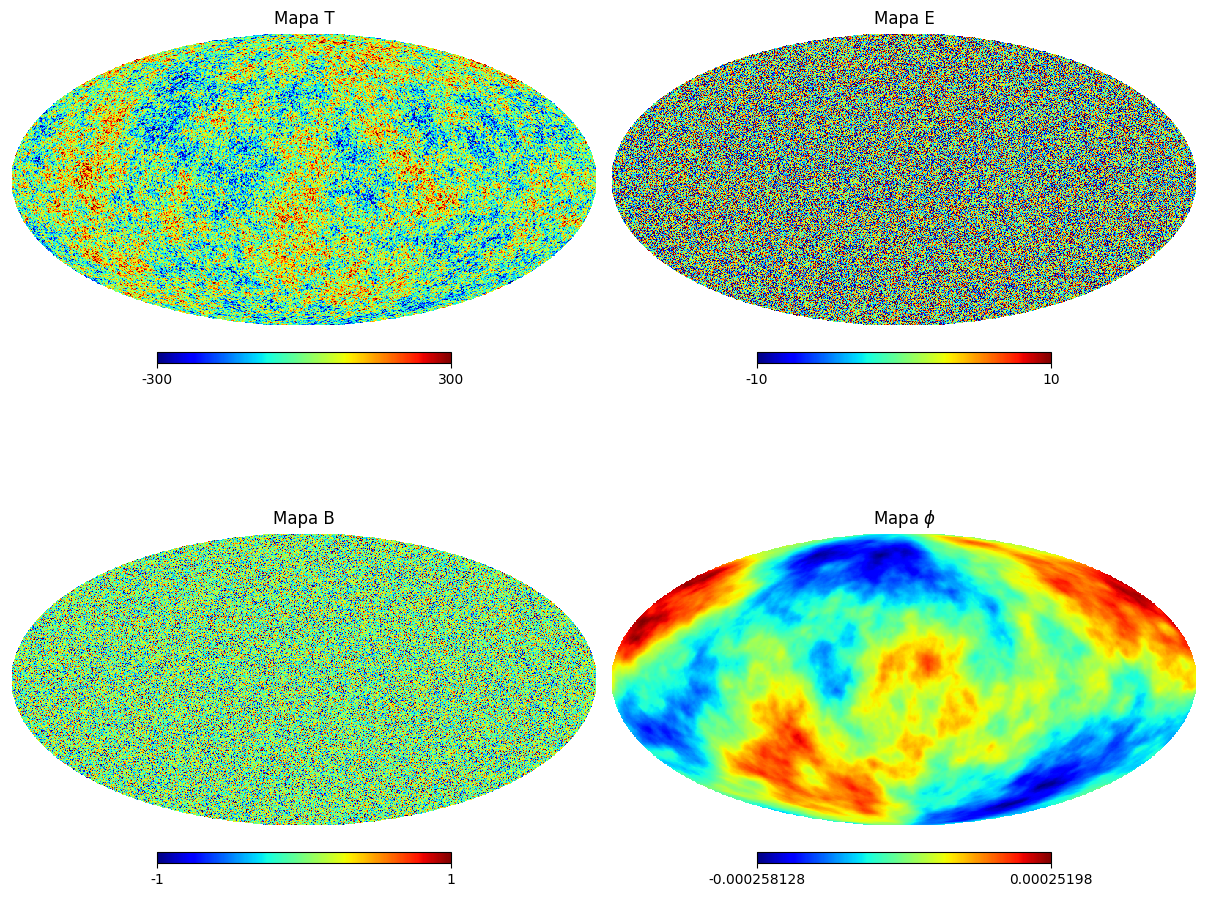

In [3]:
# Instancia de CmbSimulator
simulator = CmbSimulator(config=config)

# Mapas de CMB (T, E, B) y potencial de lensing para una realizacion.
sim = 1

alm_lensed = simulator.simulate_one(cls=[cl_unl, cl_phi], sim = sim)

almT = alm_lensed[0]
almE = alm_lensed[1]
almB = alm_lensed[2]
alm_phi = alm_lensed[3]

nside = config.cmb.nside
lmax  = config.cmb.lmax

map_T  = hp.alm2map(almT, nside=nside, lmax=lmax)
map_E  = hp.alm2map(almE, nside=nside, lmax=lmax)
map_B  = hp.alm2map(almB, nside=nside, lmax=lmax)
map_ph = hp.alm2map(alm_phi, nside=nside, lmax=lmax)

plt.figure(figsize=(12, 10))
hp.mollview(map_T,  title="Mapa T",   min=-300, max=300, sub=(2, 2, 1), cmap="jet")
hp.mollview(map_E,  title="Mapa E",   min=-10, max=10, sub=(2, 2, 2), cmap="jet")
hp.mollview(map_B,  title="Mapa B",   min=-1, max=1, sub=(2, 2, 3), cmap="jet")
hp.mollview(map_ph, title="Mapa $\phi$", sub=(2, 2, 4), cmap="jet")
plt.show()


## Foreground

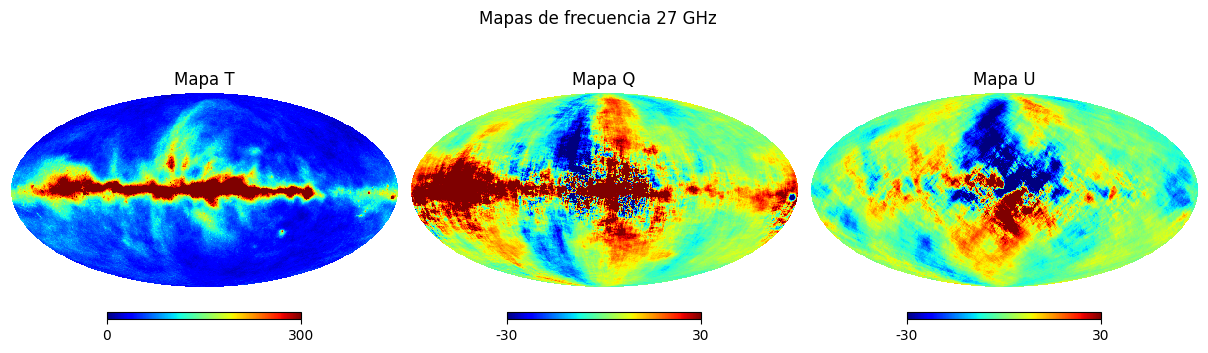

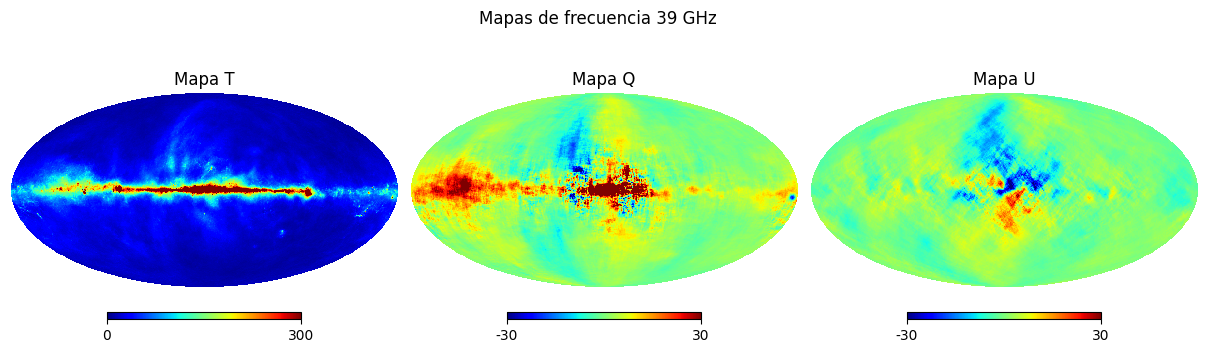

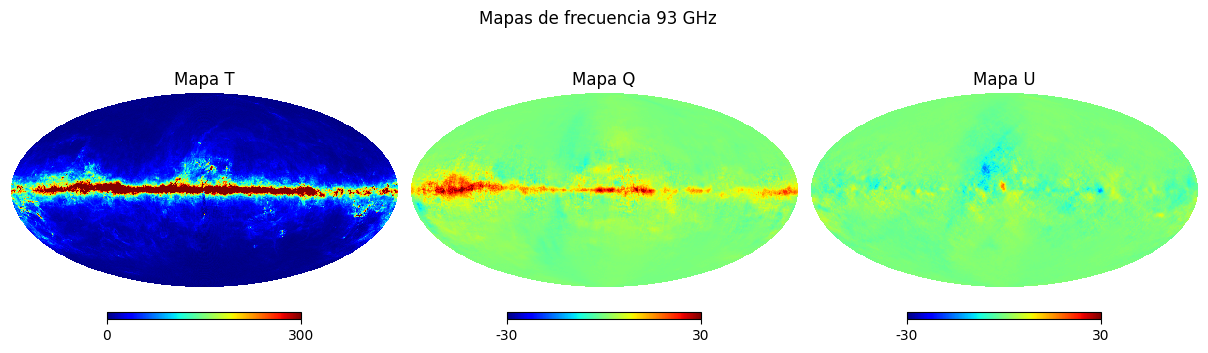

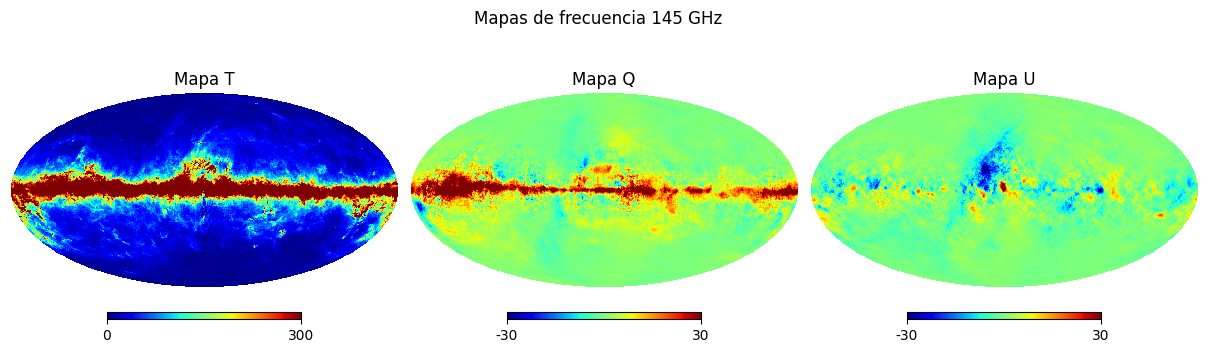

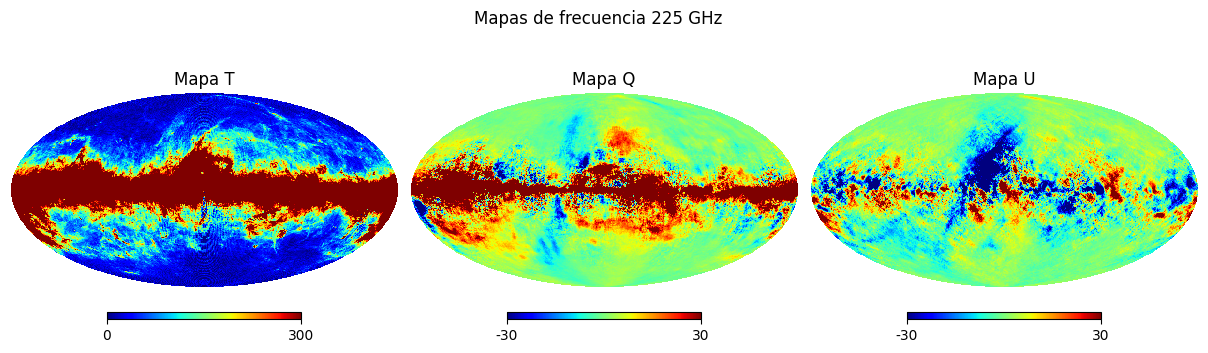

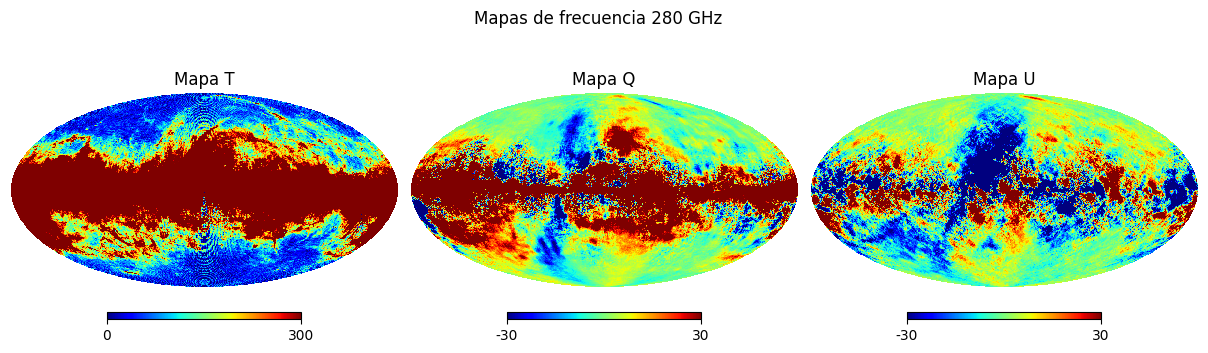

In [ ]:
# Configuración
cmb_config = CmbConfig(
    nside=256,
    nsim=1,
    lmax=500,
    r=0.00,
)

foreground_config = ForegroundConfig(
    models=["s1", "d1"],
    freq=[27, 39, 93, 145, 225, 280],
    nside=256,
    lmax=500,
    nsim=1,
)

config = Config(
    base_dir="outputs_main",
    cmb=cmb_config,
    foreground=foreground_config,
)

# Instancia del simulador
simulator = ForegroundSimulator(Config=config)

sim = 1

# Genera los alms T, E, B de todas las frecuencias
foreground_alms = simulator.simulate_one(
    sim=sim,
    save=False,
    overwrite=False,
)

# Visualizar cada frecuencia
for freq in foreground_config.freq:

    # Recuperar los alms desde el diccionario
    alm_T, alm_E, alm_B = foreground_alms[str(freq)]

    # Convertir TEB alms a mapas TQU
    map_T, map_Q, map_U = hp.alm2map(
        [alm_T, alm_E, alm_B],
        nside=foreground_config.nside,
        lmax=foreground_config.lmax,
        pol=True,
        pixwin=False,
    )

    plt.figure(figsize=(12, 10))
    plt.suptitle(f"Mapas de frecuencia {freq} GHz", y=0.85)

    hp.mollview(map_T,title="Mapa T", min=0,max=300, sub=(2, 3, 1), cmap="jet")

    hp.mollview(map_Q,title="Mapa Q", min=-30,max=30, sub=(2, 3, 2), cmap="jet")

    hp.mollview(map_U,title="Mapa U", min=-30,max=30, sub=(2, 3, 3), cmap="jet")

    plt.show()

    

## Noise

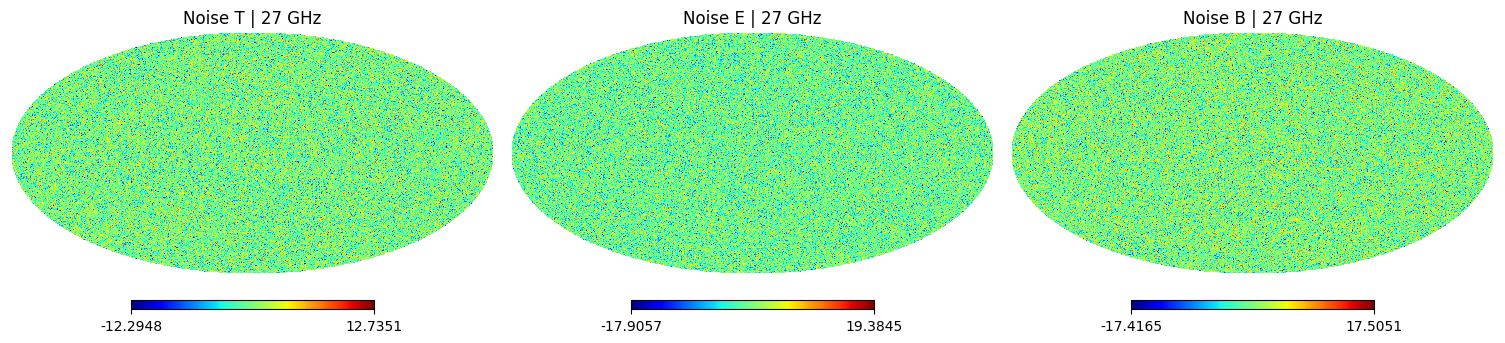

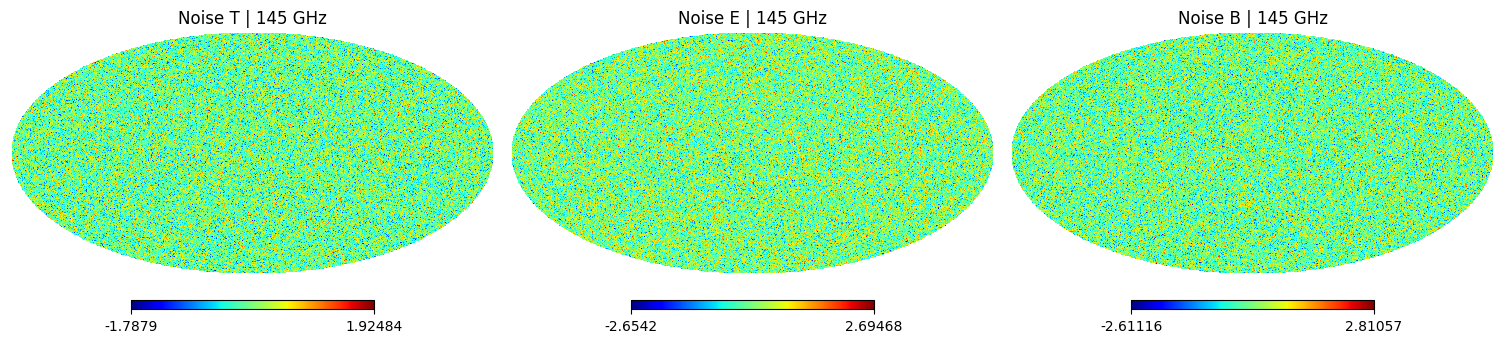

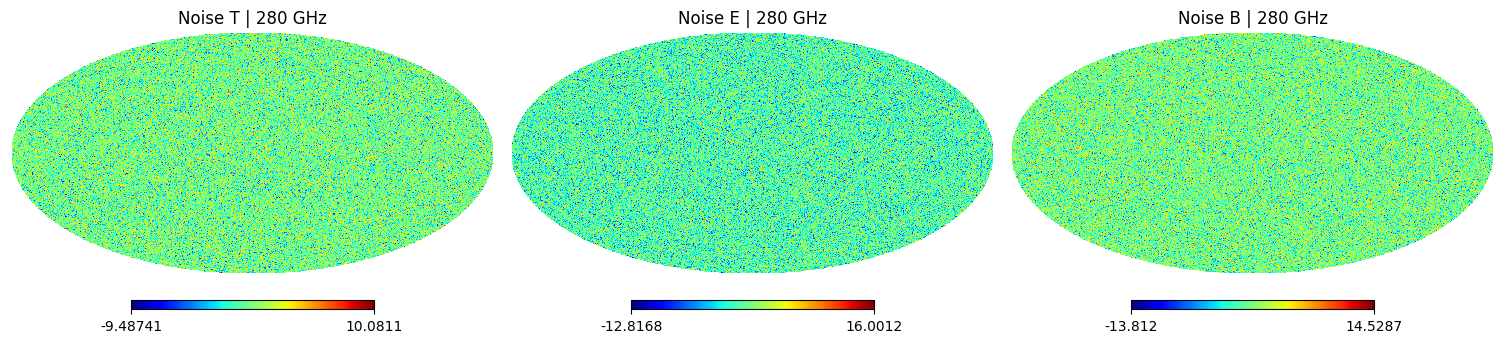

In [5]:
from src.simulations.noise_simulator import NoiseSimulator
from src.simulations.config import NoiseConfig

# Generate white-noise maps for SO LAT (MBAC) if not present yet.
noise_config = NoiseConfig(
    model="white",
    experiment="SO_LAT",
    freq=[27, 39, 93, 145, 225, 280],
    noise_t=[71, 36, 8.0, 10, 22, 54],
    noise_p=np.array([71, 36, 8.0, 10, 22, 54]) * np.sqrt(2),
    nside=config.cmb.nside,
    lmax=config.cmb.lmax,
    nsim=1,
)
sim_config = Config(base_dir=config.base_dir, noise=noise_config)

noise_simulator = NoiseSimulator(sim_config)

# Plot the noise maps (T, E, B) for a few frequencies.
freqs = [27, 145, 280]

for f in freqs:

    alm_noise = noise_simulator.simulate_one(sim=1, frequency_ghz=f)

    fig = plt.figure(figsize=(15, 5))

    for i, name in enumerate(["alm_T", "alm_E", "alm_B"]):

        m = hp.alm2map(alm_noise[i], nside=config.cmb.nside, lmax=config.cmb.lmax, pol=False)

        hp.mollview(m, title=f"Noise {name[4]} | {f} GHz", sub=(1, 3, i+1), cmap="jet")
    plt.show()


## Observed maps

Para graficar mapas observados, se utiliza observed_alm desde la clase cleaning.

## Cleaning

# ILC Cleaning

Clean maps shape: (3, 50331648)
[LOAD] CMB spectra: /home/jorge/Escritorio/Proy_cosmo/Cosmo_MSc/outputs_main/simulations/cmb/cls/r_0.00000/lmax_3000.npz


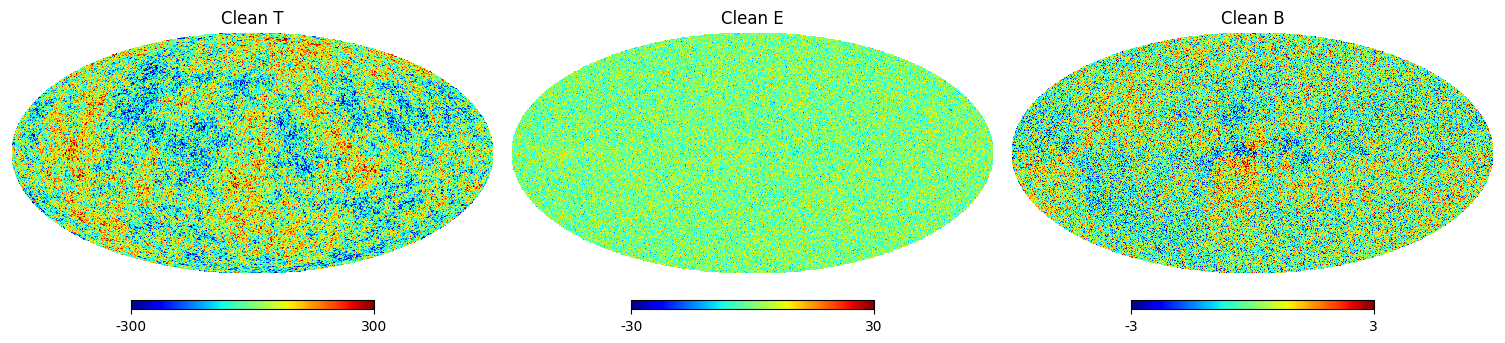

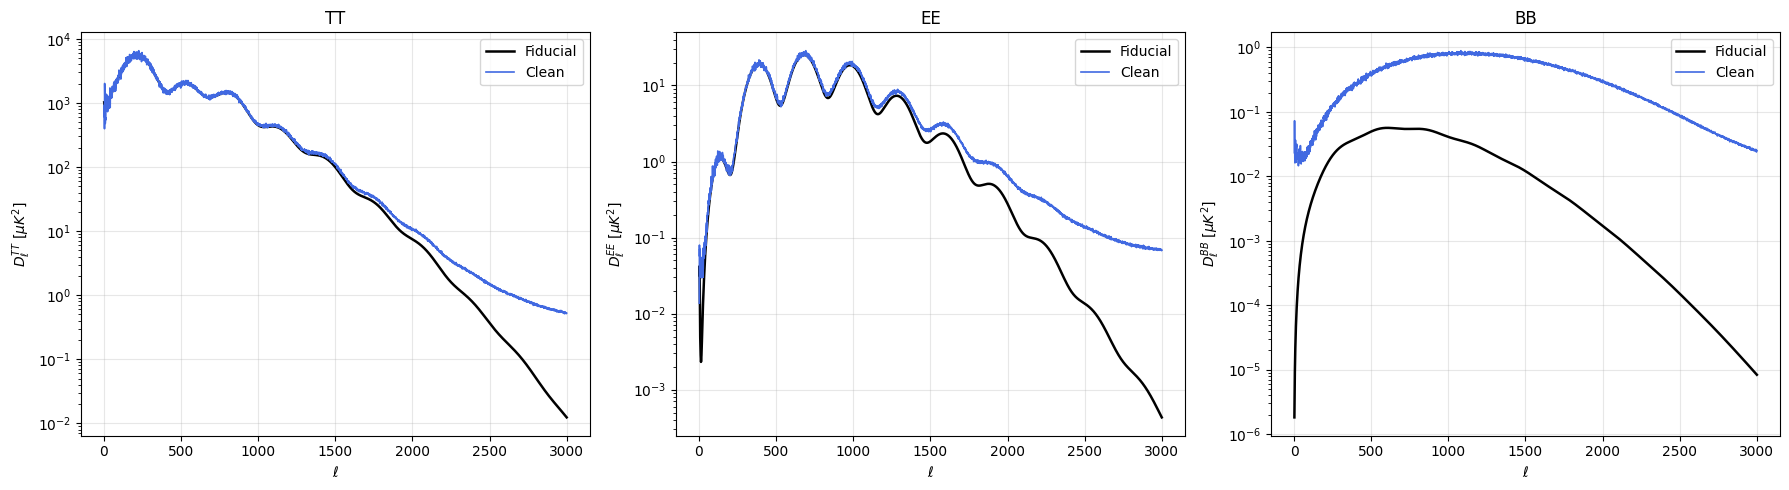

In [10]:
from pathlib import Path

sim = 1

nside = config.cmb.nside
lmax = config.cmb.lmax

beam_out = 7.4
pixel_window = True

names = ["T", "E", "B"]

files_dir = Path(
    "outputs_main/products/component_separation/"
    "ilc_pixel_bias0.0/cmb_reconstruction"
)

# Load cleaned T, E, B maps
file_clean = paths.path_output_cs(files_dir=files_dir,name="output_total",sim=sim,lmax=lmax,nside=nside,beam_out=beam_out)

maps_clean = np.asarray(hp.read_map(file_clean, field=(0, 1, 2)))

# Expected shape: (3, npix)
print("Clean maps shape:", maps_clean.shape)


# obtain lensed theoretical spectra from CAMB

cmb_simulator = CmbSimulator(config=config)

powers = cmb_simulator.compute_cls(names=["total"],overwrite=False)

cl_fid = powers["total"]  # TT, EE, BB, TE

ells = np.arange(lmax + 1)

factor = ells * (ells + 1) / (2 * np.pi)


# Common beam and optional pixel window
beam = hp.gauss_beam(fwhm=np.deg2rad(beam_out / 60.0),lmax=lmax,pol=True)

transfer = [beam[:, 0], beam[:, 1], beam[:, 2]]

# Include pixel window only if it was explicitly
# applied in the simulated observations.
if pixel_window:

    pix_T, pix_P = hp.pixwin(nside,pol=True,lmax=lmax)

    transfer[0] = transfer[0] * pix_T
    transfer[1] = transfer[1] * pix_P
    transfer[2] = transfer[2] * pix_P

# Theoretical spectra at common resolution

Dl_fid = [factor * cl_fid[:, i] * transfer[i]**2 for i in range(3)]


# Cleaned spectra

cl_clean = [hp.anafast(maps_clean[i],lmax=lmax,pol=False)for i in range(3)]

Dl_clean = [factor * cl_clean[i]for i in range(3)]


# Plot cleaned T, E, B maps

vlim = {"T": 300, "E": 30, "B": 3}

fig = plt.figure(figsize=(15, 5))

for i, name in enumerate(names):

    vl = vlim[name]
    hp.mollview(maps_clean[i],title=f"Clean {name}",min=-vl,max=vl,fig=fig.number,sub=(1, 3, i + 1),cmap="jet")
plt.show()
plt.close(fig)


# Compare cleaned spectra with fiducial spectra

fig, axes = plt.subplots(1, 3,figsize=(18, 5),sharex=True)

for i, name in enumerate(names):

    ax = axes[i]

    ax.plot(ells[2:],Dl_fid[i][2:],color="black",lw=1.8,label="Fiducial")

    ax.plot(ells[2:],Dl_clean[i][2:],color="royalblue",lw=1.2,label="Clean")

    ax.set_yscale("log")
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel(rf"$D_\ell^{{{name}{name}}}$"r" [$\mu K^2$]")

    ax.set_title(f"{name}{name}")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


# NILC Cosine Cleaning

ValueError: x and y must have same first dimension, but have shapes (2988,) and (3001, 12)

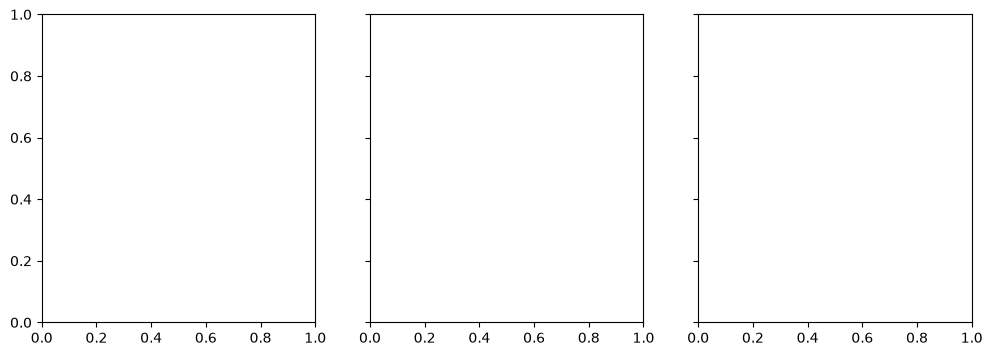

In [6]:
from broom.needlets import _get_needlet_windows_
import matplotlib.pyplot as plt
import numpy as np

lmax = 3000

# Cosine needlets
needlet_config = {}
needlet_config["needlet_windows"] = "cosine"
needlet_config["ell_peaks"] = [0, 30, 60, 100, 180, 300, 500, 800, 1200, 1800, 2400, 3000]
bl_cos = _get_needlet_windows_(needlet_config=needlet_config, lmax=lmax)
ells = np.arange(12, lmax)


# Standard needlets
needlet_config = {}
needlet_config["needlet_windows"] = "standard"
needlet_config["width"] = 2. 
needlet_config["merging_needlets"] = [0, 5] 
bl_stand = _get_needlet_windows_(needlet_config=needlet_config, lmax=lmax)

# Mexican needlets
needlet_config = {}
needlet_config["needlet_windows"] = "mexican"
needlet_config["width"] = 1.3 
needlet_config["merging_needlets"] = [0, 14, 17, 19, 40] #
bl_mex = _get_needlet_windows_(needlet_config=needlet_config, lmax=lmax)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
ax1.plot(ells,bl_cos.T)
ax2.plot(ells,bl_stand.T)
ax3.plot(ells,bl_mex.T)

ax1.set_xlim(2,config.lmax)
ax1.set_ylim(0.,1.)

ax1.set_title("Cosine needlets")
ax2.set_title("Standard needlets")
ax3.set_title("Mexican needlets")

fig.supxlabel(r"$\ell$")
fig.supylabel(r"$b(\ell)$")
plt.tight_layout()


In [ ]:
# Remember always to check that np.sum(needlet_bands**2,axis=0) = 1 at each ell so as to recover the full CMB signal

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
ax1.plot(ells,np.sum(bl_cos**2,axis=0))
ax2.plot(ells,np.sum(bl_stand**2,axis=0))
ax3.plot(ells,np.sum(bl_mex**2,axis=0))

ax1.set_xlim(2,config.lmax)
ax1.set_ylim(0.9,1.1)

ax1.set_title("Cosine needlets")
ax2.set_title("Standard needlets")
ax3.set_title("Mexican needlets")

fig.supxlabel(r"$\ell$")
fig.supylabel(r"$b(\ell)$")
plt.tight_layout()

Clean maps shape: (3, 50331648)
[LOAD] CMB spectra: /home/jorge/Escritorio/Proy_cosmo/Cosmo_MSc/outputs_main/simulations/cmb/cls/r_0.00000/lmax_3000.npz


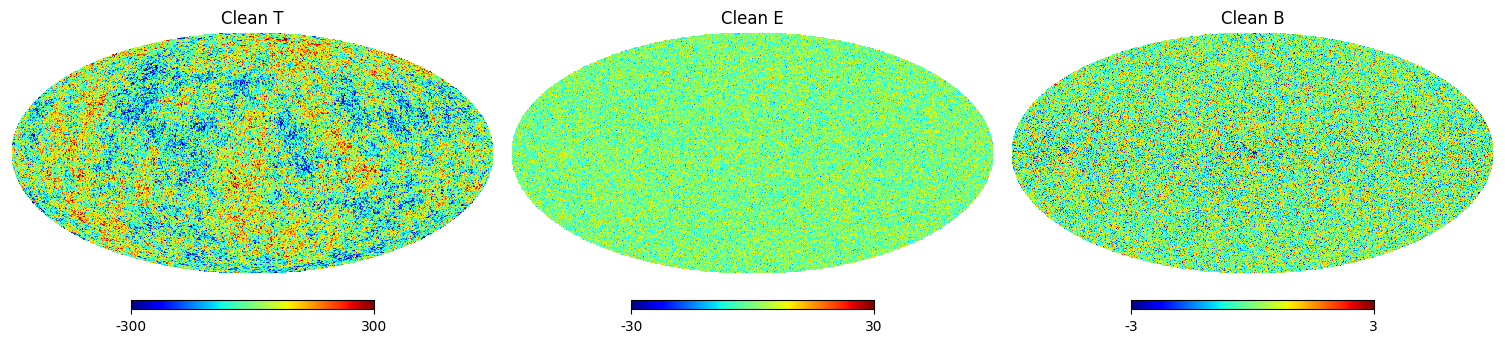

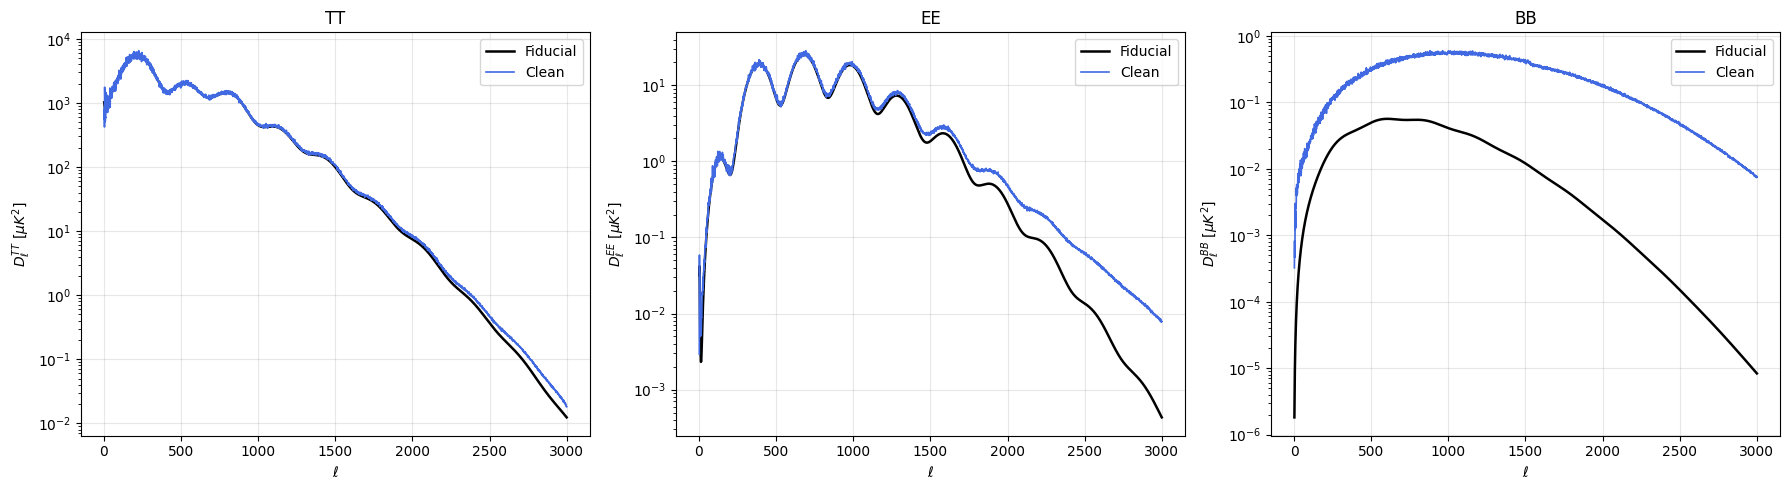

In [12]:
from pathlib import Path

sim = 1

nside = config.cmb.nside
lmax = config.cmb.lmax

beam_out = 7.4
pixel_window = True

names = ["T", "E", "B"]

files_dir = Path("outputs_main/products/component_separation/ilc_needlet_bias0.001/cosine_0_30_60_100_180_300_500_800_1200_1800_2400_3000/cmb_reconstruction"
)

# Load cleaned T, E, B maps
file_clean = paths.path_output_cs(files_dir=files_dir,name="output_total",sim=sim,lmax=lmax,nside=nside,beam_out=beam_out)

maps_clean = np.asarray(hp.read_map(file_clean, field=(0, 1, 2)))

# Expected shape: (3, npix)
print("Clean maps shape:", maps_clean.shape)


# obtain lensed theoretical spectra from CAMB

cmb_simulator = CmbSimulator(config=config)

powers = cmb_simulator.compute_cls(names=["total"],overwrite=False)

cl_fid = powers["total"]  # TT, EE, BB, TE

ells = np.arange(lmax + 1)

factor = ells * (ells + 1) / (2 * np.pi)


# Common beam and optional pixel window
beam = hp.gauss_beam(fwhm=np.deg2rad(beam_out / 60.0),lmax=lmax,pol=True)

transfer = [beam[:, 0], beam[:, 1], beam[:, 2]]

# Include pixel window only if it was explicitly
# applied in the simulated observations.
if pixel_window:

    pix_T, pix_P = hp.pixwin(nside,pol=True,lmax=lmax)

    transfer[0] = transfer[0] * pix_T
    transfer[1] = transfer[1] * pix_P
    transfer[2] = transfer[2] * pix_P

# Theoretical spectra at common resolution

Dl_fid = [factor * cl_fid[:, i] * transfer[i]**2 for i in range(3)]


# Cleaned spectra

cl_clean = [hp.anafast(maps_clean[i],lmax=lmax,pol=False)for i in range(3)]

Dl_clean = [factor * cl_clean[i]for i in range(3)]


# Plot cleaned T, E, B maps

vlim = {"T": 300, "E": 30, "B": 3}

fig = plt.figure(figsize=(15, 5))

for i, name in enumerate(names):

    vl = vlim[name]
    hp.mollview(maps_clean[i],title=f"Clean {name}",min=-vl,max=vl,fig=fig.number,sub=(1, 3, i + 1),cmap="jet")
plt.show()
plt.close(fig)


# Compare cleaned spectra with fiducial spectra

fig, axes = plt.subplots(1, 3,figsize=(18, 5),sharex=True)

for i, name in enumerate(names):

    ax = axes[i]

    ax.plot(ells[2:],Dl_fid[i][2:],color="black",lw=1.8,label="Fiducial")

    ax.plot(ells[2:],Dl_clean[i][2:],color="royalblue",lw=1.2,label="Clean")

    ax.set_yscale("log")
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel(rf"$D_\ell^{{{name}{name}}}$"r" [$\mu K^2$]")

    ax.set_title(f"{name}{name}")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path

sim   = 1
nside = config.cmb.nside
lmax  = config.cmb.lmax
beam_out = 7.4  # fwhm_out de BROOM
names = ["T", "E", "B"]

files_dir = Path(
    "/outputs_main/products/Comp_sep broom simulations/ilc_needlet_bias0.001/cosine_0_30_60_100_180_300_500_800_1200_1800_2400_3000/cmb_reconstruction"
)

def load_cs_maps(name):
    path = paths.path_output_cs(
        files_dir=files_dir, name=name,
        sim=sim, lmax=lmax, nside=nside, beam_out=beam_out,
    )
    m = hp.read_map(path, field=None)  # (3, npix) -> T, E, B
    return m if m.ndim == 2 else m[None, :]

maps_cl = load_cs_maps("output_total")       # T, E, B limpios
maps_fg = load_cs_maps("fgds_residuals")     # T, E, B residuo foreground
maps_ns = load_cs_maps("noise_residuals")    # T, E, B residuo ruido

# Input (lenteado real) desde alms
alm_len = np.load(path_alm_len / f"lmax_{lmax}_sim_{sim:04d}.npz")
alms_in = [alm_len[f"alm_{n}"] for n in names]
maps_in = [hp.alm2map(a, nside=nside, lmax=lmax) for a in alms_in]

maps_re = [maps_cl[i] - maps_in[i] for i in range(3)]

# ---------- (a) Mapas: Input vs Clean + Residuo ----------
vlim = {"T": 300, "E": 30, "B": 3}
fig = plt.figure(figsize=(18, 10))
for j, name in enumerate(names):
    vl = vlim[name]
    hp.mollview(maps_in[j], title=f"Input {name}", min=-vl, max=vl, sub=(3, 3, 3*j+1), cmap="jet")
    hp.mollview(maps_cl[j], title=f"Clean {name}", min=-vl, max=vl, sub=(3, 3, 3*j+2), cmap="jet")
    hp.mollview(maps_re[j], title=f"Residuo {name}", min=-vl, max=vl, sub=(3, 3, 3*j+3), cmap="jet")
plt.show()

# ---------- (b) Espectros: input, clean, residuo, fgds y ruido ----------
factor = ells * (ells + 1) / (2 * np.pi)

# Filtro (beam) no es necesario el pixel  
b = hp.gauss_beam(fwhm=beam_out * np.pi / (180 * 60), lmax=lmax, pol=True)
# pixT, pixP = hp.pixwin(nside, pol=True, lmax=lmax)
Filter = [b[:, 0], b[:, 1], b[:, 2]]

def cl_from_maps(maps):
    return [hp.alm2cl(hp.almxfl(hp.map2alm(maps[i], lmax=lmax), Filter[i]))
            * factor for i in range(3)]

Cl_in  = [hp.alm2cl(hp.almxfl(alms_in[i], Filter[i]), lmax=lmax) * factor
          for i in range(3)]
Cl_raw = [hp.alm2cl(hp.map2alm(maps_cl[i], lmax=lmax), lmax=lmax) * factor
          for i in range(3)]
Cl_res = [hp.alm2cl(hp.map2alm(maps_re[i], lmax=lmax), lmax=lmax) * factor
          for i in range(3)]
Cl_fg  = cl_from_maps(maps_fg)
Cl_ns  = cl_from_maps(maps_ns)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for j, name in enumerate(names):
    ax = axes[j]
    ax.plot(ells[20:], Cl_in[j][20:],  color="black", lw=1.5, label="Input (CAMB lensed)")
    ax.plot(ells[20:], Cl_raw[j][20:], color="#91c0ff", lw=1.2, label="Clean (raw)")
    ax.plot(ells[20:], Cl_res[j][20:], color="purple",  ls=":", label="Residual total")
    ax.plot(ells[20:], Cl_fg[j][20:],  color="orange", ls="--", label="Foreground residual")
    ax.plot(ells[20:], Cl_ns[j][20:],  color="green",  ls="--", label="Noise residual")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\ell$")
    ax.set_title(rf"$D_\ell^{{{name}{name}}}$")
    ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

NameError: name 'config' is not defined

## Wiener filter

## Lensing Potential / Reconstruction (Full sky)
El primero corresponde al test usando solo CMB en los estimadores cuadraticos.

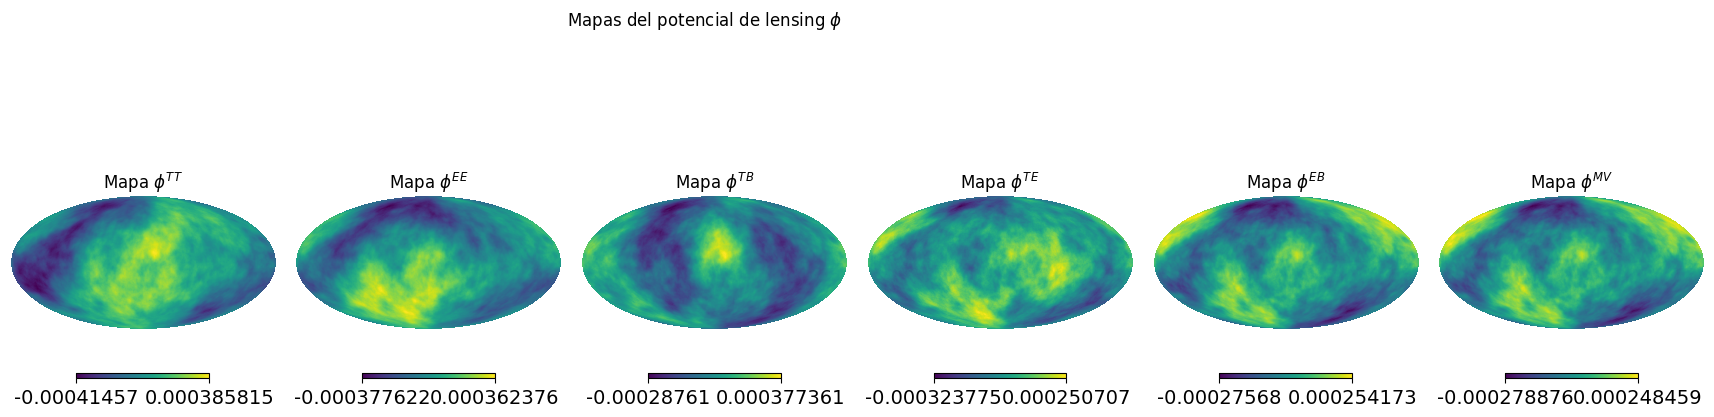

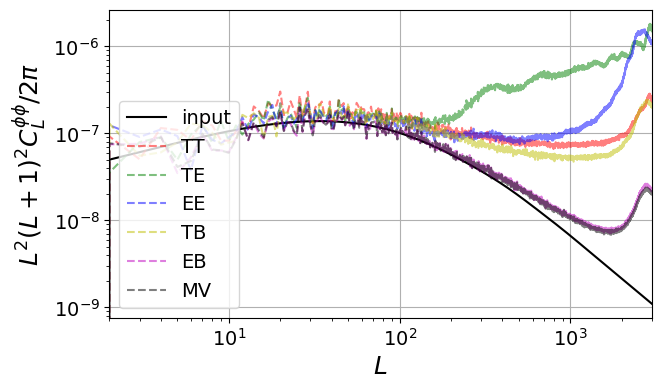

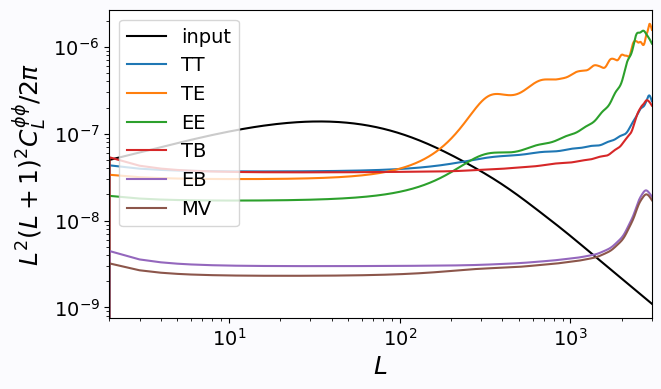

In [18]:
from curvedsky import  utils
import pymaster as nmt

from src.simulations.config import LensingConfig
import plottools as pl
from matplotlib.pyplot import *

fid_dir = "outputs_main/simulations/cmb/cls/r_0.00000"

sim   = 1
nside = config.cmb.nside
lmax  = config.cmb.lmax

lens_cfg = LensingConfig(
    nside=nside,
    lmax=lmax,
    rlmin=100,
    rlmax=lmax,
    elmin=100,
    elmax=lmax,
    QDO=(True, True, True, True, True, False),
    nsim=1,
    start_sim=0,
    fwhm_out=7.4,
    Folder_name="TEST_CMB_ONLY_LENS",
)

lens_dir = paths.cmb_lensing_dir(estimator=lens_cfg.Folder_name)

L = np.linspace(0,lmax,lmax+1)
Lfac = (L*(L+1))**2/(2*np.pi)

# map_phi = np.load

plt.figure(figsize=(20,18))
plt.suptitle(r"Mapas del potencial de lensing $\phi$",y=0.75)
# hp.mollview(map_phi, title=rf"Mapa $\phi$", sub=(2,7,1)) #min=-3e-4, max=3e-4,

# DATA data = np.load(os.path.join(ruta, f"rec_pot_{5}.npz"))
pot_data = np.load(os.path.join(lens_dir, f"potential_{sim}.npz"))
curl_data = np.load(os.path.join(lens_dir, f"curl_{sim}.npz"))
pot_norm_data = np.load(os.path.join(lens_dir, f"potential_norm_{sim}.npz"))
curl_norm_data = np.load(os.path.join(lens_dir, f"curl_norm_{sim}.npz"))

names = np.array(["TT", "EE", "TB", "TE", "EB","MV"]) #, "EE", "TB", "TE", "EB","MV"

gg, Ag, cc, Ac = {}, {}, {}, {}

for i, name in enumerate(names):

    Ag[name] = pot_norm_data[f"Ag{name}"]

    glm = pot_data[f"glm{name}"]

    gg[name] = utils.alm2cl(lmax,glm)

    map = utils.hp_alm2map(nside=nside,lmax=lmax,mmax=lmax,alm=glm)

    hp.mollview(map, title=rf"Mapa $\phi^{{{name}}}$", sub=(2,7,i+2)) # min=-3e-4, max=3e-4,

plt.show()

# plot spectra (gradient)
figure(facecolor="#ffffff")
pl.plot_1dstyle(fsize=[7,4],xmin=2,xmax=lmax,xlog=True,ylog=True,grid=True,ylab=r'$L^2(L+1)^2C^{\phi\phi}_L/2\pi$') #ymin=1e-9,ymax=1e-6
plot(L,cl_phi*Lfac,color="black",ls='-',label='input')
for qi, (c, q) in enumerate([('r','TT'),('g','TE'),('b','EE'),('y','TB'),('m','EB'),('k','MV')]):
    plot(L,Lfac*gg[q],color=c,ls='--',label=q,alpha=.5)
    # plot(L,Lfac*Ag[qi,:],color=c,ls='-')
legend(loc="lower left")

# plot normalization (gradient)
figure(facecolor="#fbfbfe")
pl.plot_1dstyle(fsize=[7,4],xmin=2,xmax=lmax,xlog=True,ylog=True,ylab=r'$L^2(L+1)^2C^{\phi\phi}_L/2\pi$')
plot(L,cl_phi*Lfac,color="black",ls='-',label='input')
for qi, q in enumerate(['TT','TE','EE','TB','EB','MV']):
    plot(L,Ag[q]*Lfac,label=q)
legend()


Esto corresponde al segundo test CMB + ruido

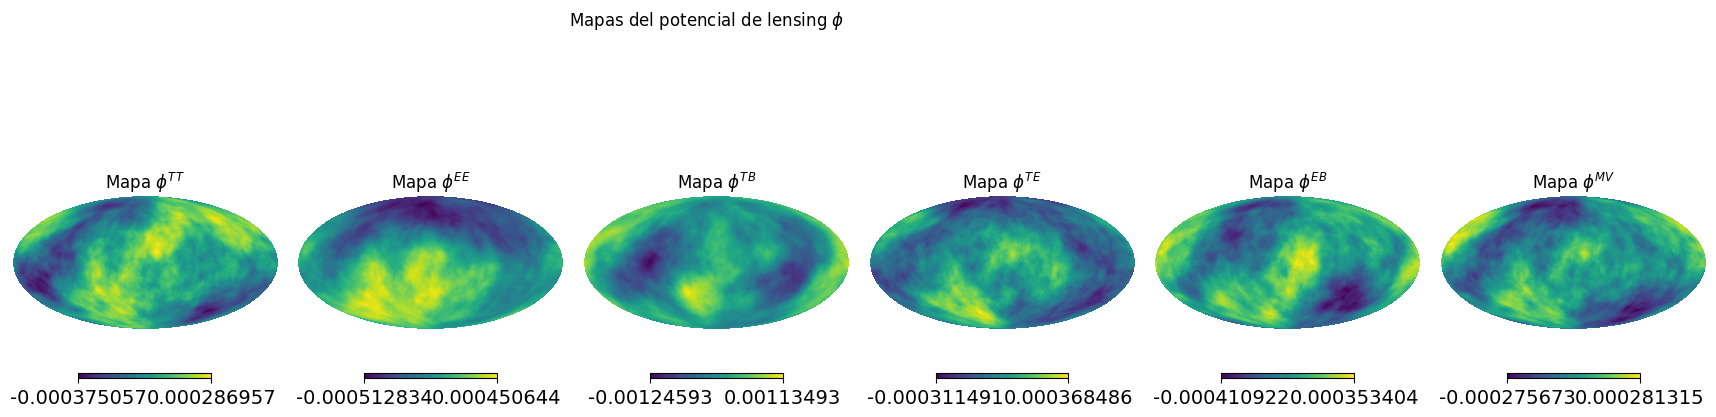

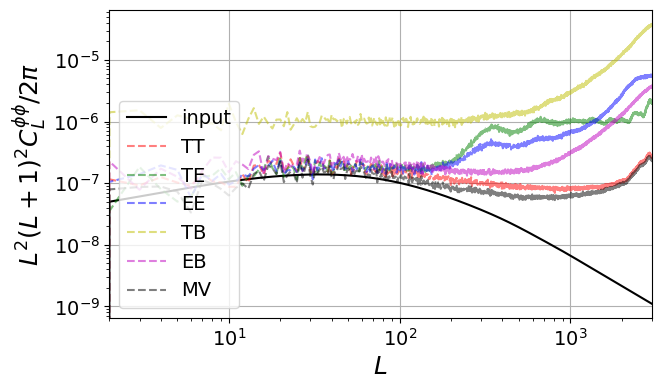

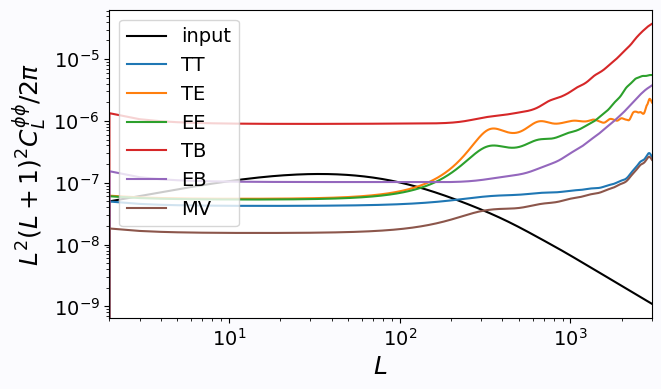

In [20]:
from curvedsky import  utils
import pymaster as nmt

from src.simulations.config import LensingConfig
import plottools as pl
from matplotlib.pyplot import *

fid_dir = "outputs_main/simulations/cmb/cls/r_0.00000"

sim   = 1
nside = config.cmb.nside
lmax  = config.cmb.lmax

lens_cfg = LensingConfig(
    nside=nside,
    lmax=lmax,
    rlmin=100,
    rlmax=lmax,
    elmin=100,
    elmax=lmax,
    QDO=(True, True, True, True, True, False),
    nsim=1,
    start_sim=0,
    fwhm_out=7.4,
    Folder_name="TEST_CMB_NOISE_93",
)

lens_dir = paths.cmb_lensing_dir(estimator=lens_cfg.Folder_name)

L = np.linspace(0,lmax,lmax+1)
Lfac = (L*(L+1))**2/(2*np.pi)

plt.figure(figsize=(20,18))
plt.suptitle(r"Mapas del potencial de lensing $\phi$",y=0.75)
# hp.mollview(map_phi, title=rf"Mapa $\phi$", sub=(2,7,1)) #min=-3e-4, max=3e-4,

# DATA data = np.load(os.path.join(ruta, f"rec_pot_{5}.npz"))
pot_data = np.load(os.path.join(lens_dir, f"potential_{sim}.npz"))
curl_data = np.load(os.path.join(lens_dir, f"curl_{sim}.npz"))
pot_norm_data = np.load(os.path.join(lens_dir, f"potential_norm_{sim}.npz"))
curl_norm_data = np.load(os.path.join(lens_dir, f"curl_norm_{sim}.npz"))

names = np.array(["TT", "EE", "TB", "TE", "EB","MV"]) #, "EE", "TB", "TE", "EB","MV"

gg, Ag, cc, Ac = {}, {}, {}, {}

for i, name in enumerate(names):

    Ag[name] = pot_norm_data[f"Ag{name}"]

    glm = pot_data[f"glm{name}"]

    gg[name] = utils.alm2cl(lmax,glm)

    map = utils.hp_alm2map(nside=nside,lmax=lmax,mmax=lmax,alm=glm)

    hp.mollview(map, title=rf"Mapa $\phi^{{{name}}}$", sub=(2,7,i+2)) # min=-3e-4, max=3e-4,

plt.show()

# plot spectra (gradient)
figure(facecolor="#ffffff")
pl.plot_1dstyle(fsize=[7,4],xmin=2,xmax=lmax,xlog=True,ylog=True,grid=True,ylab=r'$L^2(L+1)^2C^{\phi\phi}_L/2\pi$') #ymin=1e-9,ymax=1e-6
plot(L,cl_phi*Lfac,color="black",ls='-',label='input')
for qi, (c, q) in enumerate([('r','TT'),('g','TE'),('b','EE'),('y','TB'),('m','EB'),('k','MV')]):
    plot(L,Lfac*gg[q],color=c,ls='--',label=q,alpha=.5)
    # plot(L,Lfac*Ag[qi,:],color=c,ls='-')
legend(loc="lower left")

# plot normalization (gradient)
figure(facecolor="#fbfbfe")
pl.plot_1dstyle(fsize=[7,4],xmin=2,xmax=lmax,xlog=True,ylog=True,ylab=r'$L^2(L+1)^2C^{\phi\phi}_L/2\pi$')
plot(L,cl_phi*Lfac,color="black",ls='-',label='input')
for qi, q in enumerate(['TT','TE','EE','TB','EB','MV']):
    plot(L,Ag[q]*Lfac,label=q)
legend()

## Problema 

La razon es el foreground residual que esta quedando en el cielo completo, introduce mucho acoplamiento en la zona galactica que arruina el estimador. SOLUCION: HACER MASCARA

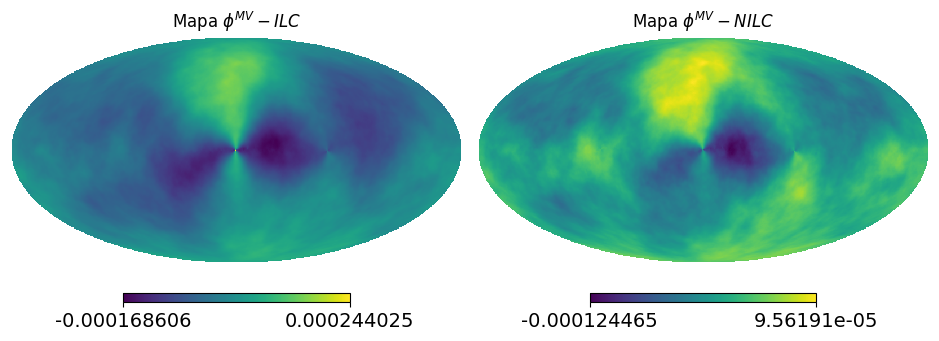

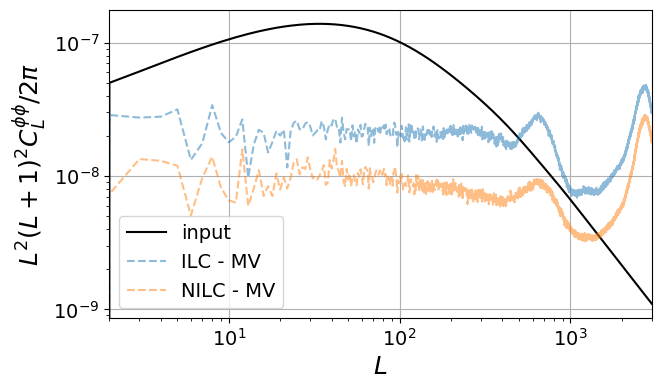

In [18]:
from curvedsky import  utils
import pymaster as nmt

from src.simulations.config import LensingConfig
import plottools as pl
from matplotlib.pyplot import *

fid_dir = "outputs_main/simulations/cmb/cls/r_0.00000"

phi_dir = "outputs_main/simulations/cmb/alms/r_0.00000/lens_potential"

ILC_dir ="outputs_main/products/Lensing reconstruction/FULL_ILC_reconstruction"

NILC_dir = "outputs_main/products/Lensing reconstruction/FULL_NILC_reconstruction"

powers = simulator.load_npz(outputs["Cls"])

cl_phi = powers["lens_potential"][:, 0]

sim   = 0
nside = config.cmb.nside
lmax  = config.cmb.lmax
L = np.linspace(0,lmax,lmax+1)
Lfac = (L*(L+1))**2/(2*np.pi)

# DATA data = np.load(os.path.join(ruta, f"rec_pot_{5}.npz"))
pot_data_ILC = np.load(os.path.join(ILC_dir, f"potential_{sim}.npz"))
pot_norm_data_ILC = np.load(os.path.join(NILC_dir, f"potential_norm_{sim}.npz"))

pot_data_NILC = np.load(os.path.join(NILC_dir, f"potential_{sim}.npz"))
pot_norm_data_NILC = np.load(os.path.join(NILC_dir, f"potential_norm_{sim}.npz"))

names = np.array(["TT", "EE", "TB", "TE", "EB","MV"]) #, "EE", "TB", "TE", "EB","MV"

gg_ILC, Ag_ILC= {}, {}

gg_NILC, Ag_NILC= {}, {}

for i, name in enumerate(names):

    Ag_ILC[name] = pot_norm_data_ILC[f"Ag{name}"]

    glm_ILC = pot_data_ILC[f"glm{name}"]

    gg_ILC[name] = utils.alm2cl(lmax,glm_ILC)

    Ag_NILC[name] = pot_norm_data_NILC[f"Ag{name}"]

    glm_NILC = pot_data_NILC[f"glm{name}"]

    gg_NILC[name] = utils.alm2cl(lmax,glm_NILC)


map_ILC = utils.hp_alm2map(nside=nside,lmax=lmax,mmax=lmax,alm=pot_data_ILC[f"glmMV"])
map_NILC = utils.hp_alm2map(nside=nside,lmax=lmax,mmax=lmax,alm=pot_data_NILC[f"glmMV"])

plt.figure(figsize=(14, 6))
hp.mollview(map_ILC, title=r"Mapa $\phi^{MV} - ILC$", sub=(1,3,1)) # min=-3e-4, max=3e-4,
hp.mollview(map_NILC, title=r"Mapa $\phi^{MV} - NILC$", sub=(1,3,2)) # min=-3e-4, max=3e-4,
plt.show()

# plot spectra (gradient)
figure(facecolor="#ffffff")
pl.plot_1dstyle(fsize=[7,4],xmin=2,xmax=lmax,xlog=True,ylog=True,grid=True,ylab=r'$L^2(L+1)^2C^{\phi\phi}_L/2\pi$') #ymin=1e-9,ymax=1e-6
plot(L,Lfac * cl_phi[:lmax+1],color="black",ls='-',label='input')
plot(L,Lfac*gg_ILC["MV"],ls='--',label="ILC - MV",alpha=.5)
plot(L,Lfac*gg_NILC["MV"],ls='--',label="NILC - MV",alpha=.5)
legend(loc="lower left")



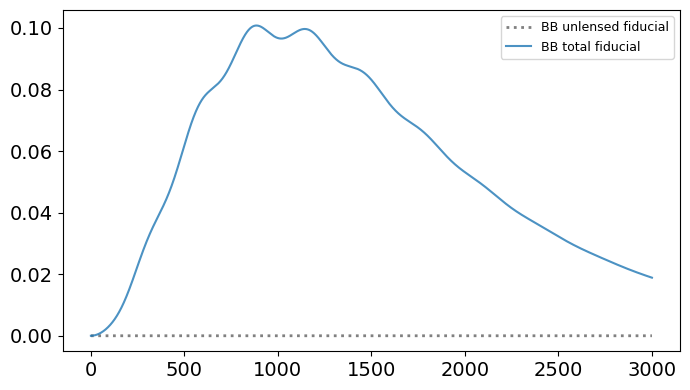

In [23]:
from curvedsky import  utils
import pymaster as nmt

from src.simulations.config import LensingConfig
import plottools as pl
from matplotlib.pyplot import *

fid_dir = "outputs_main/simulations/cmb/cls/r_0.00000"

phi_dir = "outputs_main/simulations/cmb/alms/r_0.00000/lens_potential"

ILC_dir ="outputs_main/products/Lensing reconstruction/FULL_ILC_reconstruction"

NILC_dir = "outputs_main/products/Lensing reconstruction/FULL_NILC_reconstruction"

powers = simulator.load_npz(outputs["Cls"])

cl_total = powers["total"] #[:, 0]
cl_unlensed = powers["unlensed_scalar"] #[:, 0]

# FIDUCIAL B
Cl_BB_lensed = cl_total[:lmax + 1, 2]
Cl_BB_unlensed = cl_unlensed[:lmax + 1, 2]

sim   = 0
nside = config.cmb.nside
lmax  = config.cmb.lmax
ell = np.arange(lmax + 1)
Dfac = ell * (ell + 1) / (2.0 * np.pi)

# DATA data = np.load(os.path.join(ruta, f"rec_pot_{5}.npz"))
del_data_ILC = np.load(os.path.join(ILC_dir, f"delensing_{sim}.npz"))

del_data_NILC = np.load(os.path.join(NILC_dir, f"delensing_{sim}.npz"))

B_temp_ILC = del_data_ILC["B_temp"]
B_del_ILC = del_data_ILC["B_del"]

Cl_Btemp_ILC = utils.alm2cl(lmax,B_temp_ILC)

Cl_Bdel_ILC = utils.alm2cl(lmax,B_del_ILC)

B_temp_NILC = del_data_NILC["B_temp"]
B_del_NILC = del_data_NILC["B_del"]

Cl_Btemp_NILC = utils.alm2cl(lmax,B_temp_NILC)

Cl_Bdel_NILC = utils.alm2cl(lmax,B_del_NILC)



eps = 1e-30

fdel_ILC = 1.0 - (
    Cl_Bdel_ILC
    / np.maximum(Cl_BB_lensed, eps)
)

fdel_NILC = 1.0 - (
    Cl_Bdel_NILC
    / np.maximum(Cl_BB_lensed, eps)
)

# plot spectra (gradient)
figure(facecolor="#ffffff")


plot(
    ell[2:],
    (Dfac * Cl_BB_unlensed)[2:],
    color="gray",
    ls=":",
    lw=2,
    label="BB unlensed fiducial",
)

plot(
    ell[2:],
    (Dfac * Cl_BB_lensed)[2:],
    ls="-",
    label="BB total fiducial",
    alpha=0.8,
)

# ------------------------------------------------------------
# ILC
# ------------------------------------------------------------

# plot(
#     ell[2:],
#     (Dfac * Cl_Btemp_ILC)[2:],
#     ls=":",
#     label="ILC - B template",
#     alpha=0.8,
# )

# plot(
#     ell[2:],
#     (Dfac * Cl_Bdel_ILC)[2:],
#     ls="--",
#     label="ILC - B delensed",
#     alpha=0.8,
# )


# # ------------------------------------------------------------
# # NILC
# # ------------------------------------------------------------

# plot(
#     ell[2:],
#     (Dfac * Cl_Btemp_NILC)[2:],
#     ls=":",
#     label="NILC - B template",
#     alpha=0.8,
# )

# plot(
#     ell[2:],
#     (Dfac * Cl_Bdel_NILC)[2:],
#     ls="--",
#     label="NILC - B delensed",
#     alpha=0.8,
# )

legend(
    loc="best",
    fontsize=9,
)

tight_layout()
show()

